In [3]:
import requests
import json
import matplotlib.pyplot as plt

In [4]:
# 동영상 ID
video_id = "Cbij3MKhdOY"

In [5]:
event_lst = [13, 15, 21, 43, 45, 52, 62, 68, 73, 97]

In [9]:
json_path = f'/source/ms/highlight/json/{video_id}.json'

In [10]:
with open(json_path, 'r') as json_file:
    data = json.load(json_file)

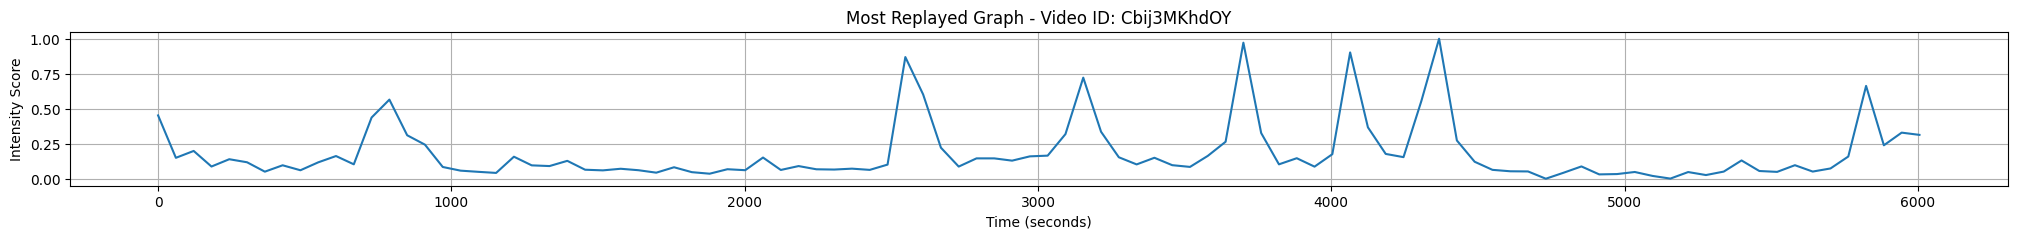

In [11]:



# # API 엔드포인트 URL
# url = f"https://yt.lemnoslife.com/videos?part=mostReplayed&id={video_id}"

# # API 호출하여 JSON 데이터 가져오기
# print('get url!!!')
# response = requests.get(url)
# print('get url finished!!!!!')
# data = response.json()

# markers 리스트에서 startMillis와 intensityScoreNormalized 값 추출
markers = data['items'][0]['mostReplayed']['markers']
start_millis = [marker['startMillis'] for marker in markers]
intensity_scores = [marker['intensityScoreNormalized'] for marker in markers]

# 밀리초를 초로 변환
start_seconds = [millis / 1000 for millis in start_millis]

# 그래프 그리기
plt.figure(figsize=(25, 2))
plt.plot(start_seconds, intensity_scores)
plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (seconds)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.show()


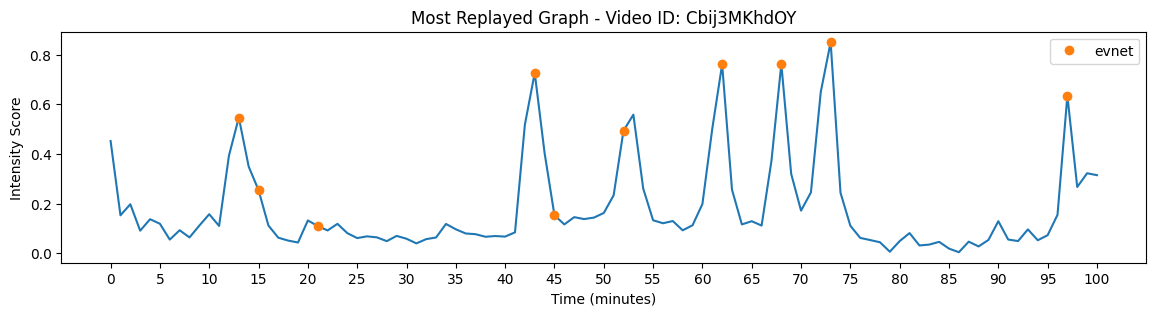

In [12]:
# 보간 함수 생성
from scipy.interpolate import interp1d
import numpy as np
from scipy.signal import find_peaks

interpolation_function = interp1d(start_seconds, intensity_scores, kind='linear', fill_value="extrapolate")

# 1초 간격으로 새로운 시간 생성
total_duration_seconds = start_seconds[-1]
total_duration_minutes = total_duration_seconds / 60
new_time = np.arange(0, total_duration_minutes, 1) * 60
# new_time = np.arange(0, total_duration_seconds, 1)

# 새로운 시간에 대한 보간된 값 계산
smoothed_intensity_scores = interpolation_function(new_time)
# peaks, _ = find_peaks(smoothed_intensity_scores, prominence = 0.1)

# 그래프 그리기
plt.figure(figsize=(14, 3))
plt.plot(new_time / 60, smoothed_intensity_scores)  # 분으로 변환하여 표시
plt.plot(np.array(event_lst) , smoothed_intensity_scores[event_lst], "o", label='evnet')
plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (minutes)')
plt.ylabel('Intensity Score')
# plt.grid(True)
plt.xticks(np.arange(0, total_duration_minutes + 1, 5))  # 5분 간격으로 x축 눈금 표시
plt.legend()
plt.show()

# normalize

In [43]:
import numpy as np

def normalize_array(arr):
    min_val = np.min(arr)
    max_val = np.max(arr)
    
    # 0으로 나누는 것을 방지하기 위한 체크
    if max_val == min_val:
        return np.zeros_like(arr)
    
    normalized_arr = (arr - min_val) / (max_val - min_val)
    return normalized_arr

# 정규화 적용
normalized_scores = normalize_array(smoothed_intensity_scores)

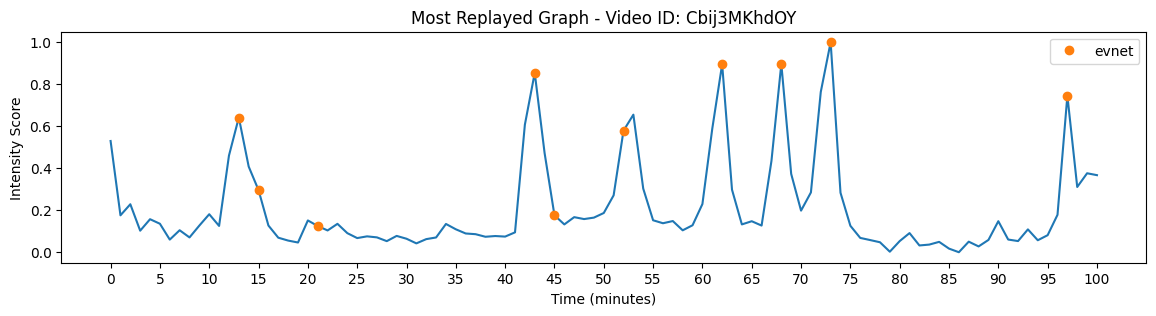

In [44]:
plt.figure(figsize=(14, 3))
plt.plot(new_time / 60, normalized_scores)  # 분으로 변환하여 표시
plt.plot(np.array(event_lst) , normalized_scores[event_lst], "o", label='evnet')
plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (minutes)')
plt.ylabel('Intensity Score')
# plt.grid(True)
plt.xticks(np.arange(0, total_duration_minutes + 1, 5))  # 5분 간격으로 x축 눈금 표시
plt.legend()
plt.show()

In [13]:
# scores = smoothed_intensity_scores
scores = smoothed_intensity_scores


In [42]:
smoothed_intensity_scores

array([0.4523012 , 0.15264691, 0.19734439, 0.09076782, 0.13701447,
       0.11870871, 0.05478669, 0.09251848, 0.06357153, 0.1114614 ,
       0.15711272, 0.10994484, 0.39346926, 0.54691234, 0.34921051,
       0.25414316, 0.1115864 , 0.06250665, 0.05086581, 0.04305263,
       0.13203853, 0.10959008, 0.09165583, 0.1183745 , 0.08085277,
       0.06092253, 0.06787607, 0.06378394, 0.0485632 , 0.06967491,
       0.05828955, 0.03955498, 0.05669836, 0.06340543, 0.11786533,
       0.09636948, 0.07947813, 0.07663214, 0.06626515, 0.06917255,
       0.06695892, 0.0840217 , 0.51796446, 0.72689242, 0.40372873,
       0.15280349, 0.1160127 , 0.14532077, 0.13756415, 0.14341883,
       0.16207655, 0.2333746 , 0.49390175, 0.55841706, 0.26034648,
       0.13275677, 0.1207479 , 0.12957923, 0.09220877, 0.11259663,
       0.19814894, 0.50199168, 0.76172009, 0.25599691, 0.11603603,
       0.12887284, 0.1113375 , 0.37219503, 0.76297671, 0.31968666,
       0.17163949, 0.24494521, 0.65016693, 0.85048119, 0.24361

In [14]:
class State:
    def __init__(self, time, count, score):
        self.time = time
        self.count = count
        self.score = score
        self.frame = 0
        self.next_states = [] # 접근할 수 있는 인덱스 저장

    def get_info(self):
        # info = f'Peak: {self.peak}, Frame: {self.frame}, Count: {self.count}, Reward: {self.reward}, Time: {self.time}, Next State {self.next_states}'
        info = f'time: {self.time}, Count: {self.count},  Next State {self.next_states}'
        print(info)




In [15]:
total_time = 30

In [16]:
max_t = total_time

In [17]:
states = [[State(time=i, count=j, score=scores[i]) for j in range(max_t + 1)] for i in range(len(scores))]


In [18]:
len(states)

101

In [19]:
min_time = 5

In [20]:
# 상태들의 next_states를 설정하는 함수
def set_next_states(states, min_time, max_t):
    n = len(states)
    for i in range(n):
        for t in range(max_t + 1):
            if i + 1 < n and t + 1 <= max_t :
                states[i][t].next_states.append((i + 1, t + 1))  # 다음 시간과 새로운 t 값
            if t >= min_time:
                for j in range(i + 2, n):
                    states[i][t].next_states.append((j, 0))  # 다음 상태의 인덱스와 새로운 t 값 0


In [21]:
set_next_states(states, min_time, max_t)

In [22]:
states[0][0].next_states

[(1, 1)]

In [23]:
import numpy as np

def select_optimal_points(states, num_points=3):
    n = len(states)
    max_t = num_points
    
    # DP 테이블과 추적 테이블 초기화
    dp = np.full((n, max_t + 1, num_points + 1), -np.inf)
    dp[:, 0, 0] = 0
    trace = np.full((n, max_t + 1, num_points + 1, 2), -1, dtype=int)  # 추적 테이블 수정

    # DP 테이블 채우기
    for i in range(n):
        for t in range(max_t + 1):
            for k in range(1, num_points + 1):
                # **수정된 부분: 유효한 상태인지 확인**
                if dp[i, t, k - 1] != -np.inf:  # 유효한 상태인 경우에만 업데이트
                    for next_i, next_t in states[i][t].next_states:
                        if next_i < n and next_t <= max_t:
                            new_score = dp[i, t, k - 1] + states[next_i][next_t].score
                            if new_score > dp[next_i, next_t, k]:
                                dp[next_i, next_t, k] = new_score
                                trace[next_i, next_t, k] = (i, t)

    # 최대 점수와 마지막 인덱스 찾기
    max_score = -np.inf
    max_index = (-1, -1, -1)
    for i in range(n):
        for t in range(max_t + 1):
            if dp[i, t, num_points] > max_score:
                max_score = dp[i, t, num_points]
                max_index = (i, t, num_points)

    # 경로 추적하여 선택된 점 찾기
    selected_points = []
    k = num_points
    while max_index != (-1, -1, -1) and k > 0:
        max_index = tuple(trace[max_index[0], max_index[1], k])
        selected_points.append(max_index[0])
        k -= 1
    
    selected_points.reverse()
    return selected_points, max_score

In [24]:
def DP(states, num_points=30):
    n = len(states)
    max_t = num_points
    
    # DP 테이블과 추적 테이블 초기화
    dp = np.full((n, max_t + 1, num_points + 1), -np.inf)
    dp[:, 0, 0] = 0
    trace = np.full((n, max_t + 1, num_points + 1, 4), -1, dtype=int)

    # DP 테이블 채우기
    for i in range(n):
        for t in range(max_t + 1):
            for k in range(1, num_points + 1):
                if dp[i, t, k - 1] != -np.inf:
                    for next_i, next_t in states[i][t].next_states:
                        # if i == 162 and t == 7 and k == num_points:
                        #     pdb.set_trace()  
                        if next_i < n and next_t <= max_t:
                            new_score = dp[i, t, k - 1] + states[next_i][next_t].score
                            if new_score > dp[next_i, next_t, k]:
                                dp[next_i, next_t, k] = new_score
                                trace[next_i, next_t, k] = (i, t, next_i, next_t)

    return dp, trace


In [25]:
def find_path(states, dp, trace, num_points=30):
    n = len(states)
    max_score = -np.inf
    max_index = (-1, -1, -1)
    max_t = num_points
    for i in range(n):
        for t in range(max_t + 1):
            if dp[i, t, num_points] > max_score:
                max_score = dp[i, t, num_points]
                max_index = (i, t, num_points)

    selected_points = []
    k = num_points
    while max_index != (-1, -1, -1) and k > 0:
        max_index = tuple(trace[max_index[0], max_index[1], k])
        selected_points.append(max_index[0])
        k -= 1
    
    selected_points.reverse()
    return selected_points, max_score

In [26]:
dp, trace = DP(states, num_points=total_time) 
selected_points, max_score = find_path(states, dp, trace, num_points=total_time)


In [27]:
max_score

11.167285521089013

In [28]:
def group_consecutive_points(points):
    grouped_points = []
    group = [points[0]]
    for i in range(1, len(points)):
        if points[i] == points[i-1] + 1:
            group.append(points[i])
        else:
            grouped_points.append(group)
            group = [points[i]]
    grouped_points.append(group)
    return grouped_points

In [29]:

selected_smoothed_scores = [smoothed_intensity_scores[i] for i in selected_points]

In [30]:
grouped_points = group_consecutive_points(selected_points)
group_sizes = [len(group) for group in grouped_points]

In [31]:
for group in grouped_points:
    group.append(group[-1]+1)

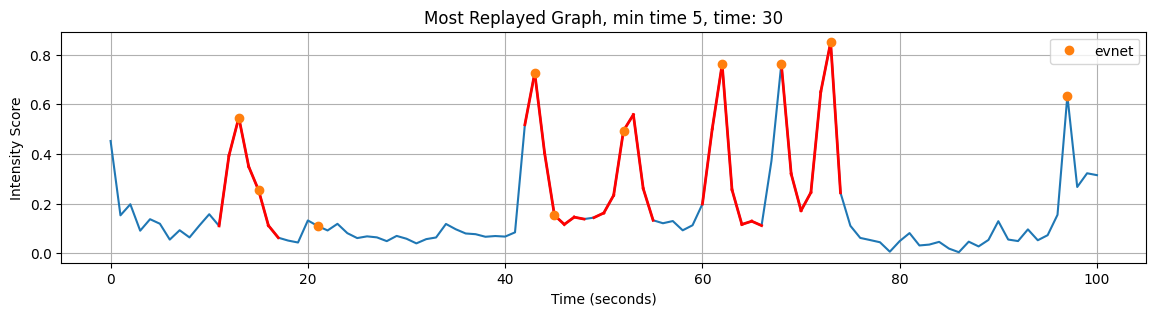

In [32]:
# 그래프 그리기
# 그래프 그리기
plt.figure(figsize=(14, 3))
plt.plot(new_time / 60, smoothed_intensity_scores)  # 분으로 변환하여 표시
# plt.scatter(selected_points, selected_smoothed_scores, color='r',  s=15, zorder=5)

# 연속된 점들의 그룹 크기를 그래프에 표시
# for group, size in zip(grouped_points, group_sizes):
#     mid_point = group[len(group) // 2]
#     plt.text(mid_point, smoothed_intensity_scores[mid_point], str(size), color='black', fontsize=20, ha='center')

for group in grouped_points:
    for i in range(len(group) -1 ):
        plt.plot([group[i], group[i + 1]], [smoothed_intensity_scores[group[i]], smoothed_intensity_scores[group[i + 1]]], color='r', linewidth=2)

plt.plot(np.array(event_lst) , smoothed_intensity_scores[event_lst], "o", label='evnet')

plt.title(f'Most Replayed Graph, min time {min_time}, time: {total_time}')
plt.xlabel('Time (seconds)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.legend()
plt.show()

# 소리 크기

In [36]:
from moviepy.editor import VideoFileClip
import librosa
import numpy as np
import matplotlib.pyplot as plt

# # 비디오 파일 경로
# video_path = "C:/Users/vml_sub/Documents/Minsun2024/highlight/source/Cbij3MKhdOY.mp4"

# # 비디오에서 오디오 추출
# video = VideoFileClip(video_path)
# audio = video.audio
# audio.write_audiofile("temp_audio.wav")



# 임시 오디오 파일 삭제
import os
# os.remove("temp_audio.wav")

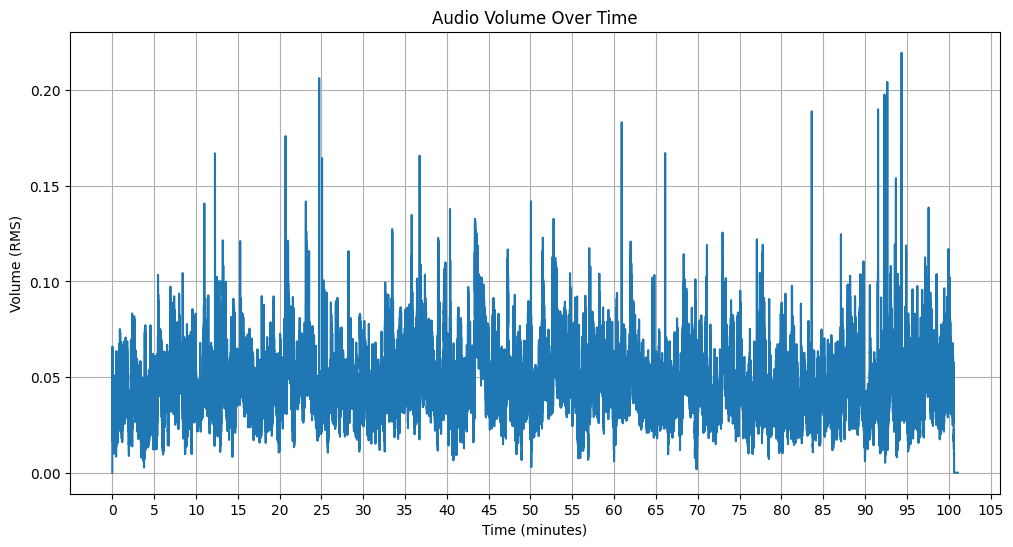

In [57]:
# 오디오 파일 로드
# y, sr = librosa.load("soccer.wav")
y, sr = librosa.load("combined_output.wav")

# 소리 크기(RMS) 계산
frame_length = int(sr * 0.05)  # 50ms 프레임
hop_length = int(sr * 0.025)  # 25ms 홉
rms = librosa.feature.rms(y=y, frame_length=frame_length, hop_length=hop_length)
rms = rms.squeeze()  # 2D에서 1D로 변환

# 시간 배열 생성 (분 단위)
times = librosa.times_like(rms, sr=sr, hop_length=hop_length) / 60

# 그래프 그리기
plt.figure(figsize=(12, 6))
plt.plot(times, rms)
plt.title("Audio Volume Over Time")
plt.xlabel("Time (minutes)")
plt.ylabel("Volume (RMS)")
plt.grid(True)

# x축 눈금 설정 (5분 간격)
max_time = times[-1]
plt.xticks(np.arange(0, max_time + 5, 5))

plt.show()

# smooth

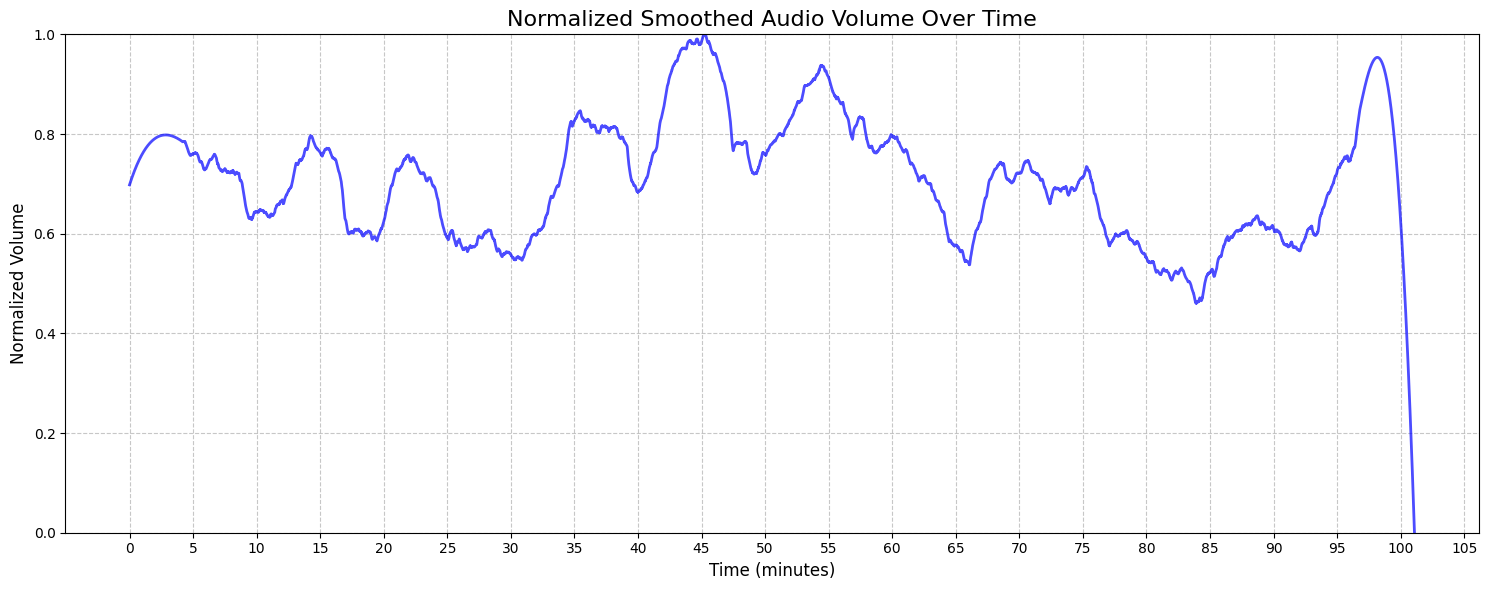

In [38]:
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
import numpy as np

# 이동 평균 적용
window_size = 20001  # 윈도우 크기 (홀수여야 함)
smoothed_rms = savgol_filter(rms, window_size, 3)  # Savitzky-Golay 필터 적용

# 0과 1 사이로 정규화
normalized_rms = (smoothed_rms - np.min(smoothed_rms)) / (np.max(smoothed_rms) - np.min(smoothed_rms))

# 그래프 그리기
plt.figure(figsize=(15, 6))
plt.plot(times, normalized_rms, color='blue', alpha=0.7, linewidth=2)
plt.title("Normalized Smoothed Audio Volume Over Time", fontsize=16)
plt.xlabel("Time (minutes)", fontsize=12)
plt.ylabel("Normalized Volume", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

# y축 범위 설정
plt.ylim(0, 1)

# x축 눈금 설정 (5분 간격)
max_time = times[-1]
plt.xticks(np.arange(0, max_time + 5, 5))

plt.tight_layout()
plt.show()

# Moving average

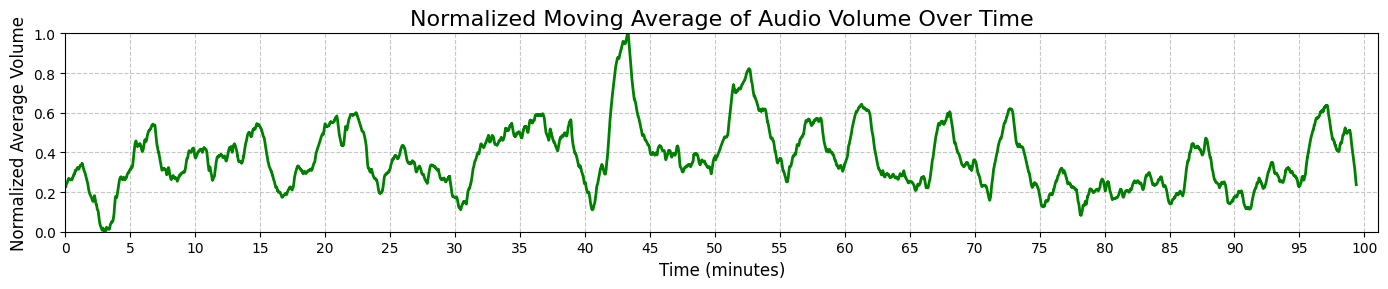

In [65]:
import numpy as np
import matplotlib.pyplot as plt

def moving_average(data, window_size):
    return np.convolve(data, np.ones(window_size), 'valid') / window_size

def normalize(data):
    return (data - np.min(data)) / (np.max(data) - np.min(data))

window_size = 4100  # 조절 가능
ma_rms = moving_average(rms, window_size)

# 0과 1 사이로 정규화
normalized_ma_rms = normalize(ma_rms)

# 결과를 완전히 왼쪽으로 이동
ma_times = times[:len(normalized_ma_rms)]

plt.figure(figsize=(14, 3))
plt.plot(ma_times, normalized_ma_rms, color='green', linewidth=2)
plt.title("Normalized Moving Average of Audio Volume Over Time", fontsize=16)
plt.xlabel("Time (minutes)", fontsize=12)
plt.ylabel("Normalized Average Volume", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(np.arange(0, max_time + 5, 5))
plt.ylim(0, 1)  # y축 범위를 0에서 1로 설정
plt.xlim(0, max_time)  # x축 범위를 0부터 max_time까지로 설정
plt.tight_layout()
plt.show()

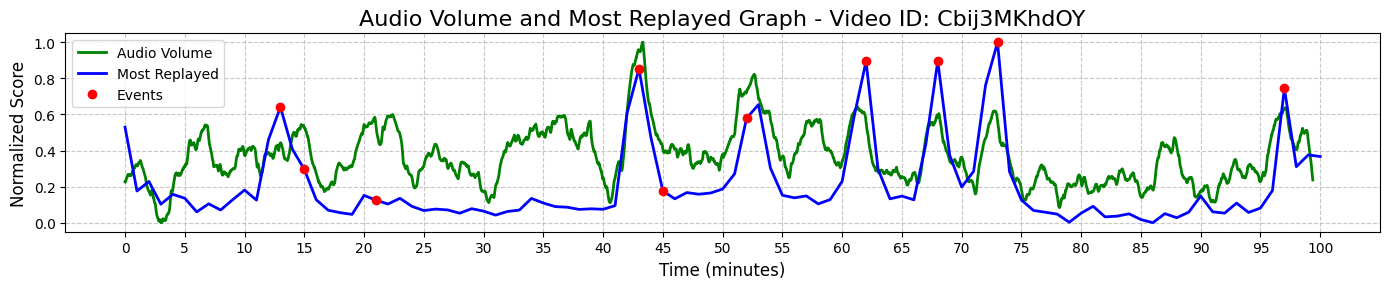

In [67]:
plt.figure(figsize=(14, 3))

# 오디오 볼륨 그래프
plt.plot(ma_times, normalized_ma_rms, color='green', linewidth=2, label='Audio Volume')

# Most Replayed 그래프
plt.plot(new_time / 60, normalized_scores, color='blue', linewidth=2, label='Most Replayed')

# 이벤트 포인트
plt.plot(np.array(event_lst), normalized_scores[event_lst], "o", color='red', label='Events')
# for group in grouped_points:
#     for i in range(len(group) -1 ):
#         plt.plot([group[i], group[i + 1]], [smoothed_intensity_scores[group[i]], smoothed_intensity_scores[group[i + 1]]], color='r', linewidth=2)

plt.title(f'Audio Volume and Most Replayed Graph - Video ID: {video_id}', fontsize=16)
plt.xlabel('Time (minutes)', fontsize=12)
plt.ylabel('Normalized Score', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(np.arange(0, total_duration_minutes + 1, 5))  # 5분 간격으로 x축 눈금 표시
plt.legend()
plt.tight_layout()
plt.show()

# 상관 관계

In [61]:
len(smoothed_intensity_scores)

101

In [62]:
target_scores = normalized_scores

In [63]:
from scipy import interpolate
from scipy import stats


def find_optimal_window_size(window):
    ma_rms = moving_average(rms, window)
    normalized_ma_rms = normalize(ma_rms)
    ma_times = times[:len(normalized_ma_rms)]
    
    if len(normalized_ma_rms) > len(target_scores):
        long_data = normalized_ma_rms
        short_data = target_scores
        long_times = ma_times
        short_times = new_time / 60
    else:
        long_data = target_scores
        short_data = normalized_ma_rms
        long_times = new_time / 60
        short_times = ma_times
    
    f = interpolate.interp1d(short_times, short_data, kind='linear', fill_value='extrapolate')
    resampled_short_data = f(long_times)
    correlation, _ = stats.pearsonr(long_data, resampled_short_data)
    return correlation

In [64]:
max_correlation = -1
optimal_window = 0

for window in range(100, 7000, 100):
    correlation = find_optimal_window_size(window)
    if correlation > max_correlation:
        max_correlation = correlation
        optimal_window = window
    print(f"Window: {window}, Correlation: {correlation}")

print(f"\nOptimal window size: {optimal_window}")
print(f"Maximum correlation: {max_correlation}")

Window: 100, Correlation: 0.2222038975997861
Window: 200, Correlation: 0.2394647740113805
Window: 300, Correlation: 0.25650107283744566
Window: 400, Correlation: 0.27311095813020525
Window: 500, Correlation: 0.28952189226189806
Window: 600, Correlation: 0.305867167525337
Window: 700, Correlation: 0.32207903188816545
Window: 800, Correlation: 0.3378911196966115
Window: 900, Correlation: 0.3532808619126707
Window: 1000, Correlation: 0.36829847945668076
Window: 1100, Correlation: 0.38302202119272605
Window: 1200, Correlation: 0.39746631754062756
Window: 1300, Correlation: 0.4114180879628622
Window: 1400, Correlation: 0.42488847184403233
Window: 1500, Correlation: 0.437900287253448
Window: 1600, Correlation: 0.45041705266496235
Window: 1700, Correlation: 0.46246408958242824
Window: 1800, Correlation: 0.47405837799886014
Window: 1900, Correlation: 0.4851744384566352
Window: 2000, Correlation: 0.4957289341009806
Window: 2100, Correlation: 0.5056899628293025
Window: 2200, Correlation: 0.51497